In [1]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))


import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import actual_vs_prediction, feature_importance, y_fdistro


In [2]:
COLUMNS = "admet_columns.json"

In [3]:
df = DataManager(path="admet/cyp3a4").dataset

with open(COLUMNS, 'r') as f:
    data = json.load(f)

df = df[data['columns']]


In [4]:
fp_cols = [col for col in df.columns if col.startswith("fp_")]
unique_cols = df[fp_cols].nunique()
constant_cols = unique_cols[unique_cols == 1]

# exclude_column(path=COLUMNS, col_name="cyp3a4", col=list(constant_cols.index))
df = df.drop(columns=constant_cols.index)

In [5]:
null = (df.isnull()).sum().sum()
null

np.int64(0)

In [6]:
X = df.drop(columns='label')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=25)

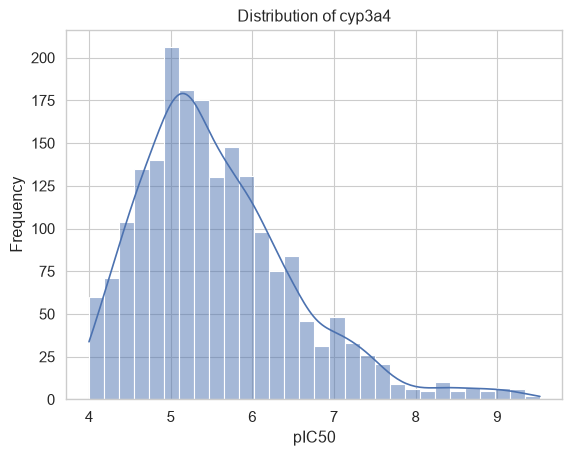

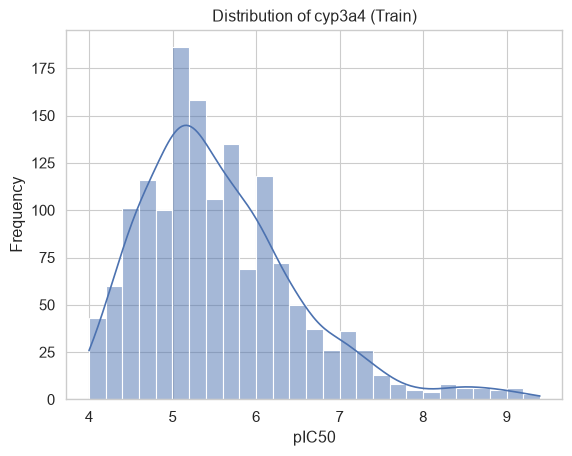

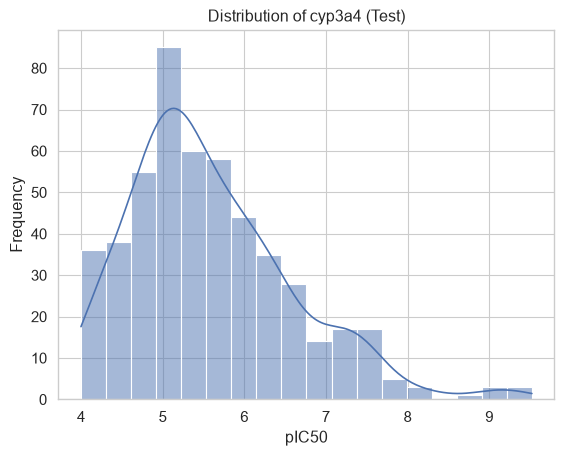

In [7]:
y_fdistro(y, "cyp3a4")
y_fdistro(y_train, "cyp3a4 (Train)")
y_fdistro(y_test, "cyp3a4 (Test)")

In [8]:
# model = RandomForestRegressor(
#     random_state=42,
#     n_jobs=-1
# )

# param_grid = {
#     "n_estimators": [1500, 2000, 2500],
#     "max_depth": [None, 5, 10, 20, 30, 50],
#     "min_samples_split": [2, 5, 10, 15],
#     "min_samples_leaf": [1, 2, 4, 8],
#     "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
#     "max_samples": [None, 0.6, 0.8, 1.0]
# }

# search = RandomizedSearchCV(
#     model,
#     param_distributions=param_grid,
#     n_iter=50,
#     scoring="neg_root_mean_squared_error",
#     cv=5,
#     random_state=42,
#     n_jobs=-1
# )

# search.fit(X_train, y_train)
# print(search.best_params_)
# print(search.best_score_)



In [9]:
best_model = RandomForestRegressor(
    n_estimators=2000,
    min_samples_split=2,
    min_samples_leaf=1, 
    max_features=0.8 
)

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [10]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')

RMSE: 0.6071791175860332
MSE: 0.3686664808325538
MAE: 0.44755140566484214
R2: 0.6350503775168896


In [11]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')

RMSE: 0.6071791175860332
MSE: 0.3686664808325538
MAE: 0.44755140566484214
R2: 0.6350503775168896


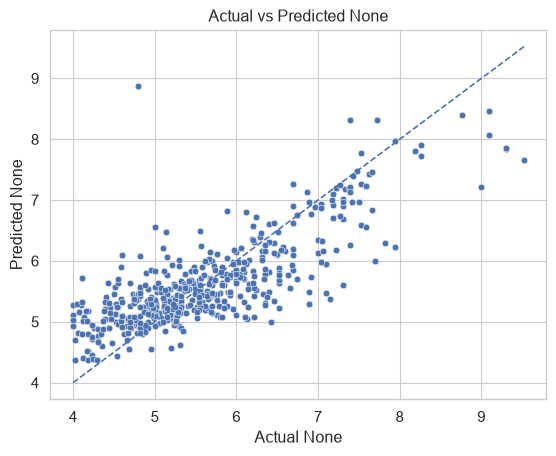

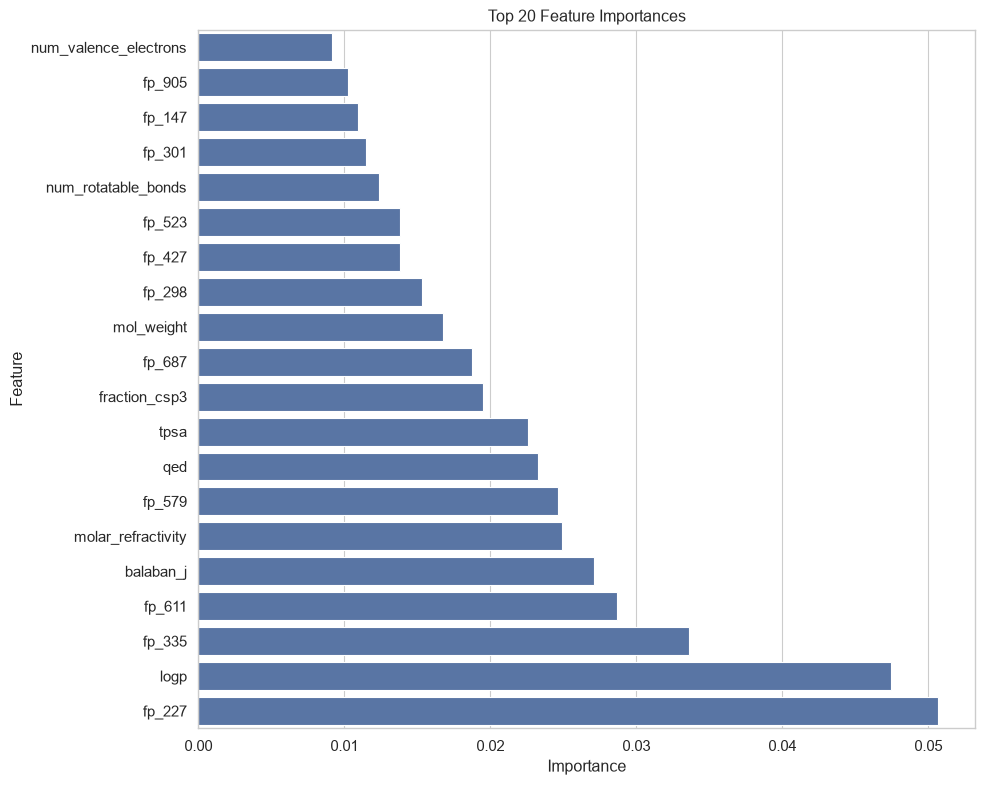

,Feature,Importance
10,num_valence_electrons,0.009134
921,fp_905,0.010233
163,fp_147,0.010908
317,fp_301,0.011488
5,num_rotatable_bonds,0.012353
539,fp_523,0.013783
443,fp_427,0.013800
314,fp_298,0.015306
0,mol_weight,0.016742
703,fp_687,0.018742


In [12]:
actual_vs_prediction(y_test, y_pred)
feature_importance(best_model, X_train.columns)